In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, TensorDataset

# 1. Carregar les dades
df = pd.read_csv('molrep_mlatom_decimals_coma.csv', encoding='latin1', sep=';')

# Separem característiques (x1 a x24) i la label
X = df.iloc[:, 1:25].values

# Fix: Convertir la columna 'labels' a numèric, gestionant els punts com a separadors de milers
df['labels'] = df['labels'].astype(str).str.replace(',', '.', regex=False).astype(float)
y = df['labels'].values.reshape(-1, 1)

# 2. Preprocessament
scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y)

# --- MODIFICACIÓ: SEPARACIÓ EN 3 CONJUNTS (Train, Val, Test) ---
# Primer separem el 15% per a la prova final (Test)
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y_scaled, test_size=0.15, random_state=42)

# Del que queda, separem un 20% per a validació durant l'entrenament
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.20, random_state=42)

# Convertir a tensors de PyTorch
X_train = torch.FloatTensor(X_train)
y_train = torch.FloatTensor(y_train)
X_val = torch.FloatTensor(X_val)
y_val = torch.FloatTensor(y_val)
X_test = torch.FloatTensor(X_test)
y_test = torch.FloatTensor(y_test)

# Creem el DataLoader amb batch size de 128
BATCH_SIZE = 128
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)

print(f"DataLoader a punt amb {len(train_loader)} batches de {BATCH_SIZE}")

# 3. Definició de la Xarxa Neuronal
class MolNetImproved(nn.Module):
    def __init__(self):
        super(MolNetImproved, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(24, 128),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

model = MolNetImproved()

# 4. Configuració de l'entrenament
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=100, gamma=0.5)

# 5. Bucle d'entrenament (AMB VALIDACIÓ SEPARADA)
epochs = 500
train_losses = []
val_losses = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # Per calcular la mitjana de l'epoch

    # --- AQUEST ÉS EL BUCLE DEL DATALOADER (Batch Size 128) ---
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()

        # Forward pass amb el batch
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)

        # Backward i optimització
        loss.backward()
        optimizer.step()

        running_loss += loss.item() # Acumulem l'error dels batches

    # Actualitzem el scheduler un cop per epoch
    scheduler.step()

    # --- FASE DE VALIDACIÓ ---
    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val)
        val_loss = criterion(val_outputs, y_val)

    # Guardem la mitjana de pèrdua de l'entrenament d'aquesta epoch
    avg_train_loss = running_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    val_losses.append(val_loss.item())

    if (epoch+1) % 50 == 0:
        print(f'Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss.item():.4f} | LR: {optimizer.param_groups[0]["lr"]}')

print("\nEntrenament finalitzat amb Mini-Batches de 128.")

# 7. Predicció final sobre el conjunt de TEST (dades mai vistes)
model.eval()
with torch.no_grad():
    test_pred_scaled = model(X_test)
    test_loss = criterion(test_pred_scaled, y_test)

    # Tornar a l'escala original per veure resultats reals
    pred_original = scaler_y.inverse_transform(test_pred_scaled)
    real_original = scaler_y.inverse_transform(y_test)

    print(f"\nError Final al conjunt de TEST (MSE): {test_loss.item():.4f}")
    print("\nExemples de prediccions al conjunt de TEST (Real vs Predicció):")
    for r, p in zip(real_original[:5], pred_original[:5]):
        print(f"Real: {r[0]:.4f} | Predicció: {p[0]:.4f}")

DataLoader a punt amb 50 batches de 128
Epoch [50/500] | Train Loss: 0.0704 | Val Loss: 0.1323 | LR: 0.005
Epoch [100/500] | Train Loss: 0.0482 | Val Loss: 0.1293 | LR: 0.0025
Epoch [150/500] | Train Loss: 0.0368 | Val Loss: 0.1344 | LR: 0.0025
Epoch [200/500] | Train Loss: 0.0345 | Val Loss: 0.1272 | LR: 0.00125
Epoch [250/500] | Train Loss: 0.0313 | Val Loss: 0.1297 | LR: 0.00125
Epoch [300/500] | Train Loss: 0.0292 | Val Loss: 0.1279 | LR: 0.000625
Epoch [350/500] | Train Loss: 0.0247 | Val Loss: 0.1294 | LR: 0.000625
Epoch [400/500] | Train Loss: 0.0263 | Val Loss: 0.1282 | LR: 0.0003125
Epoch [450/500] | Train Loss: 0.0233 | Val Loss: 0.1288 | LR: 0.0003125
Epoch [500/500] | Train Loss: 0.0248 | Val Loss: 0.1294 | LR: 0.00015625

Entrenament finalitzat amb Mini-Batches de 128.

Error Final al conjunt de TEST (MSE): 0.1397

Exemples de prediccions al conjunt de TEST (Real vs Predicció):
Real: 0.5653 | Predicció: 0.5676
Real: 0.5229 | Predicció: 0.5398
Real: 0.5205 | Predicció: 0.52

In [ ]:
from sklearn.metrics import mean_absolute_error

model.eval()
with torch.no_grad():
    y_pred_all = model(X_test)
    # Tornem a l'escala original per mesurar l'error real
    y_pred_inv = scaler_y.inverse_transform(y_pred_all)
    y_real_inv = scaler_y.inverse_transform(y_test)

    mae = mean_absolute_error(y_real_inv, y_pred_inv)
    print(f"L'error mitjà és de: {mae:.4f} unitats")

L'error mitjà és de: 0.0376 unitats


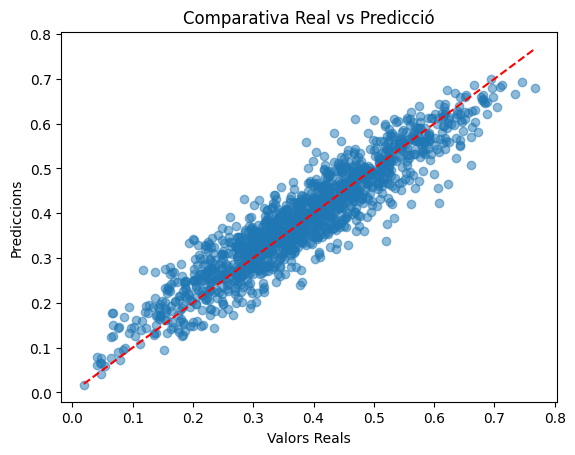

In [ ]:
plt.scatter(y_real_inv, y_pred_inv, alpha=0.5)
plt.plot([y_real_inv.min(), y_real_inv.max()], [y_real_inv.min(), y_real_inv.max()], 'r--')
plt.xlabel('Valors Reals')
plt.ylabel('Prediccions')
plt.title('Comparativa Real vs Predicció')
plt.show()

In [ ]:
# 1. Nova Arquitectura més robusta
class MolNetImproved(nn.Module):
    def __init__(self):
        super(MolNetImproved, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(24, 128),
            nn.ReLU(),
            nn.Dropout(0.1), # Ajuda a generalitzar
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)

model = MolNetImproved()
optimizer = optim.Adam(model.parameters(), lr=0.005) # LR una mica més alt inicialment
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=100, gamma=0.5) # Cada 100 èpoques, baixa el ritme
criterion = nn.MSELoss()

# 2. Entrenament més llarg
epochs = 500
losses = []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train)
    loss = criterion(outputs, y_train)
    loss.backward()
    optimizer.step()
    scheduler.step() # Actualitzem el ritme d'aprenentatge

    losses.append(loss.item())
    if (epoch+1) % 50 == 0:
        print(f'Epoch [{epoch+1}/{500}], Loss: {loss.item():.4f}, LR: {optimizer.param_groups[0]["lr"]}')

print("Entrenament finalitzat. Torna a calcular el MAE.")

Epoch [50/500], Loss: 0.2469, LR: 0.005
Epoch [100/500], Loss: 0.1771, LR: 0.0025
Epoch [150/500], Loss: 0.1582, LR: 0.0025
Epoch [200/500], Loss: 0.1406, LR: 0.00125
Epoch [250/500], Loss: 0.1327, LR: 0.00125
Epoch [300/500], Loss: 0.1321, LR: 0.000625
Epoch [350/500], Loss: 0.1275, LR: 0.000625
Epoch [400/500], Loss: 0.1255, LR: 0.0003125
Epoch [450/500], Loss: 0.1248, LR: 0.0003125
Epoch [500/500], Loss: 0.1259, LR: 0.00015625
Entrenament finalitzat. Torna a calcular el MAE.


In [ ]:
# Generem prediccions per a TOTES les dades del fitxer
model.eval()
with torch.no_grad():
    X_all_tensor = torch.FloatTensor(X)
    pred_all_scaled = model(X_all_tensor)
    pred_all = scaler_y.inverse_transform(pred_all_scaled)

# Creem un DataFrame per guardar-ho
resultats = pd.DataFrame({
    'Nom_Molecula': df['name'],
    'Valor_Real': df['labels'],
    'Prediccio_IA': pred_all.flatten(),
    'Error_Absolut': np.abs(df['labels'] - pred_all.flatten())
})

resultats.to_csv('resultats_prediccio.csv', index=False)
print("Fitxer 'resultats_prediccio.csv' creat. Baixa'l des de la carpeta de l'esquerra!")

Fitxer 'resultats_prediccio.csv' creat. Baixa'l des de la carpeta de l'esquerra!


In [ ]:
torch.save(model.state_dict(), 'meu_model_quimic.pth')

In [ ]:
# Agafem la primera fila de les teves dades per provar
fila_exemple = X_test[0].unsqueeze(0) # Preparem la dada per al model

model.eval()
with torch.no_grad():
    prediccio_escalada = model(fila_exemple)
    valor_real = scaler_y.inverse_transform(y_test[0].reshape(-1, 1))
    valor_predit = scaler_y.inverse_transform(prediccio_escalada)

print(f"--- PROVA INDIVIDUAL ---")
print(f"Valor que hi havia a l'Excel: {valor_real[0][0]:.4f}")
print(f"Valor que diu la teva IA: {valor_predit[0][0]:.4f}")

--- PROVA INDIVIDUAL ---
Valor que hi havia a l'Excel: 0.5653
Valor que diu la teva IA: 0.5733


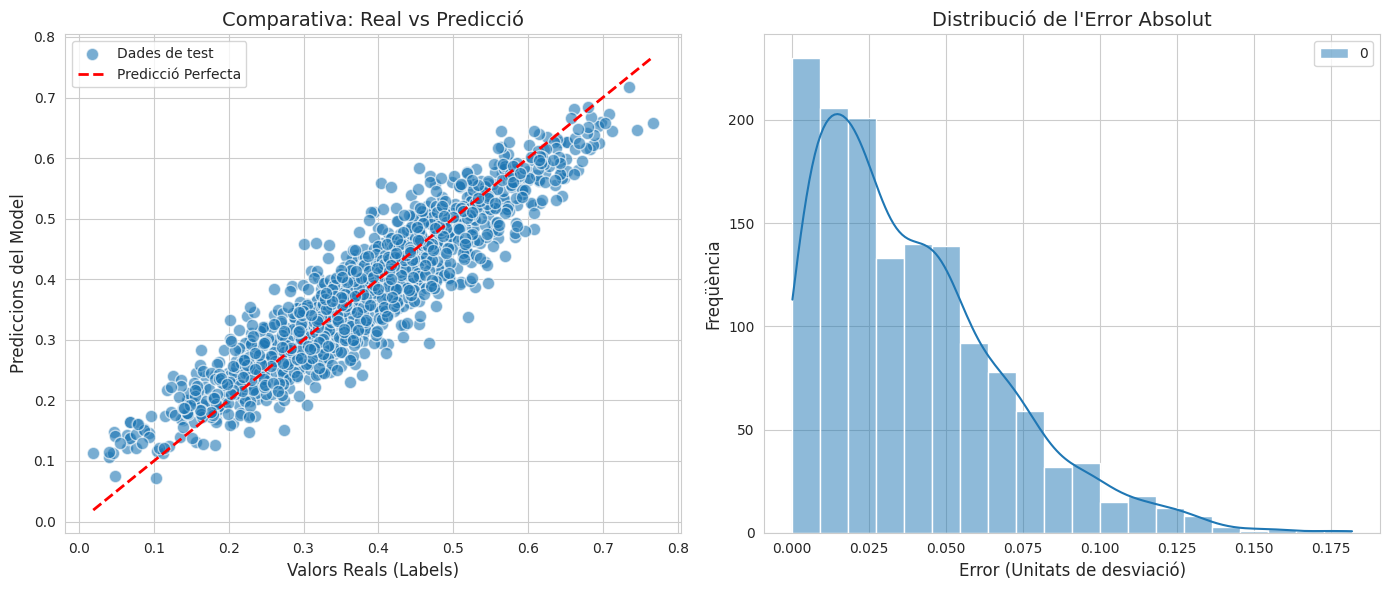

RESUM FINAL:
-> Error Mitjà (MAE): 0.0384
-> Error Màxim: 0.1818
-> Correlació (R²): 0.8636


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Obtenir totes les prediccions del set de test
model.eval()
with torch.no_grad():
    y_pred_scaled = model(X_test)
    y_pred = scaler_y.inverse_transform(y_pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

# 2. Configurar l'estil visual
plt.figure(figsize=(14, 6))
sns.set_style("whitegrid")

# --- SUBPLOT 1: Parity Plot ---
plt.subplot(1, 2, 1)
plt.scatter(y_true, y_pred, alpha=0.6, edgecolors='w', s=80, label='Dades de test')
plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw=2, label='Predicció Perfecta')
plt.title('Comparativa: Real vs Predicció', fontsize=14)
plt.xlabel('Valors Reals (Labels)', fontsize=12)
plt.ylabel('Prediccions del Model', fontsize=12)
plt.legend()

# --- SUBPLOT 2: Histograma de l'Error ---
errors = np.abs(y_true - y_pred)
plt.subplot(1, 2, 2)
sns.histplot(errors, kde=True, color='teal', bins=20)
plt.title('Distribució de l\'Error Absolut', fontsize=14)
plt.xlabel('Error (Unitats de desviació)', fontsize=12)
plt.ylabel('Freqüència', fontsize=12)

plt.tight_layout()
plt.show()

print(f"RESUM FINAL:")
print(f"-> Error Mitjà (MAE): {errors.mean():.4f}")
print(f"-> Error Màxim: {errors.max():.4f}")
print(f"-> Correlació (R²): {np.corrcoef(y_true.flatten(), y_pred.flatten())[0,1]**2:.4f}")


In [ ]:
from google.colab import files
torch.save(model.state_dict(), 'model_molecular_entrenat.pth')
files.download('model_molecular_entrenat.pth')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
model.eval()
with torch.no_grad():
    # Passem totes les dades pel model
    totes_les_x = torch.FloatTensor(X)
    prediccions_final_scaled = model(totes_les_x)
    prediccions_final = scaler_y.inverse_transform(prediccions_final_scaled)

# Creem la taula per comparar
comparativa = pd.DataFrame({
    'Nom Molècula': df['name'],
    'Valor Real (Excel)': df['labels'],
    'Predicció Model': prediccions_final.flatten()
})

# Calculem el percentatge d'error per a cada fila
comparativa['% Error'] = (np.abs(comparativa['Valor Real (Excel)'] - comparativa['Predicció Model']) / comparativa['Valor Real (Excel)']) * 100

# Mostrem les primeres 10 files
print(comparativa.head(10))

                  Nom Molècula  Valor Real (Excel)  Predicció Model   % Error
0  lin.cc.2.23.2.1.000-010-001            0.510140         0.465390  8.772084
1  lin.cc.2.23.2.1.000-101-000            0.377116         0.374944  0.575851
2  lin.cc.2.23.2.1.001-010-000            0.535529         0.496404  7.305698
3  lin.cc.2.23.2.1.010-000-010            0.651319         0.599049  8.025159
4  lin.cc.2.23.2.2.001-010-011            0.381267         0.349184  8.414685
5  lin.cc.2.23.2.2.001-100-110            0.347644         0.377219  8.507331
6  lin.cc.2.23.2.2.010-001-110            0.475993         0.455923  4.216628
7  lin.cc.2.23.2.2.100-000-111            0.462093         0.461173  0.199143
8  lin.cc.2.23.2.2.100-010-011            0.449240         0.468902  4.376856
9  lin.cc.2.23.2.2.100-010-101            0.442296         0.468390  5.899697


In [ ]:
# Calculem l'error absolut per a totes les files
comparativa['Error_Absolut'] = np.abs(comparativa['Valor Real (Excel)'] - comparativa['Predicció Model'])

# Ordenem per error de major a menor i agafem les 5 primeres
top_errors = comparativa.sort_values(by='Error_Absolut', ascending=False).head(5)

print("--- LES 5 MOLÈCULES AMB MÉS ERROR ---")
print(top_errors[['Nom Molècula', 'Valor Real (Excel)', 'Predicció Model', 'Error_Absolut']])


--- LES 5 MOLÈCULES AMB MÉS ERROR ---
                     Nom Molècula  Valor Real (Excel)  Predicció Model  \
4745  lin.ct.7.27.7.1.100-100-000            0.376297         0.592612   
4029  lin.ct.3.47.7.1.000-100-100            0.473606         0.676098   
7637  lin.tt.2.43.3.1.100-000-100            0.384330         0.584342   
3877  lin.ct.3.37.7.3.111-110-100            0.207408         0.391859   
733   lin.cc.2.43.7.2.001-100-101            0.519716         0.337919   

      Error_Absolut  
4745       0.216315  
4029       0.202492  
7637       0.200013  
3877       0.184452  
733        0.181797  


In [ ]:
def predir_nova_molecula(descriptors_llista):
    """
    descriptors_llista: una llista amb 24 números (x1 a x24)
    """
    model.eval()
    with torch.no_grad():
        # Convertir la llista a tensor
        entrada = torch.FloatTensor([descriptors_llista])
        # Predicció
        pred_scaled = model(entrada)
        # Desnormalitzar
        pred_final = scaler_y.inverse_transform(pred_scaled)

    return pred_final[0][0]

# EXEMPLE D'ÚS:
# Copiem els descriptors de la primera fila del teu Excel (o inventa'n uns de nous)
exemple_x = X[0].tolist()
resultat = predir_nova_molecula(exemple_x)

print(f"\n--- PREDICCIÓ DE NOVA MOLÈCULA ---")
print(f"La predicció de la IA per a aquests descriptors és: {resultat:.4f}")


--- PREDICCIÓ DE NOVA MOLÈCULA ---
La predicció de la IA per a aquests descriptors és: 0.4654


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Carregar dades
data = pd.read_csv('molrep_mlatom_decimals_coma.csv', encoding='latin1', sep=';') # Added encoding for robustness
# Fix: Convertir la columna 'labels' a numèric, gestionant els punts com a separadors de milers
data['labels'] = data['labels'].astype(str).str.replace(',', '.', regex=False).astype(float)
X = data.drop(columns=['name', 'labels']).values
y = data['labels'].values.reshape(-1, 1)

# Normalitzem també la 'y' per ajudar la xarxa a convergir més ràpid
scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y)

results_mse = []

num_epochs = 500 # Define num_epochs

for i in range(3):
    print(f"\n--- EXECUCIÓ {i+1} ---")

    X_train, X_val, y_train, y_val = train_test_split(X, y_scaled, test_size=0.2, random_state=42+i)

    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32)
    X_val_t = torch.tensor(X_val, dtype=torch.float32)
    y_val_t = torch.tensor(y_val, dtype=torch.float32)

    # Arquitectura: 2 HL x 21, ReLU
    model = nn.Sequential(
        nn.Linear(X_train.shape[1], 21),
        nn.ReLU(),
        nn.Linear(21, 21),
        nn.ReLU(),
        nn.Linear(21, 1)
    )

    # Baixem una mica el learning rate (lr) si l'error és molt brusc
    optimizer = optim.Adam(model.parameters(), lr=0.005)
    criterion = nn.MSELoss()

    best_val_loss = float('inf')
    patience = 20
    counter = 0

    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()
        outputs = model(X_train_t)
        loss = criterion(outputs, y_train_t)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_outputs = model(X_val_t)
            val_loss = criterion(val_outputs, y_val_t)

        # Edita el print per veure ambdues pèrdues
        if (epoch + 1) % 50 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {loss.item():.4f}, Val Loss: {val_loss.item():.4f}')

        # Early stopping logic should be here, after calculating val_loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                break

    # Desfem la normalització per veure l'MSE real (en unitats originals)
    model.eval()
    with torch.no_grad():
        pred_scaled = model(X_val_t)
        pred_final = scaler_y.inverse_transform(pred_scaled)
        y_val_final = scaler_y.inverse_transform(y_val)

        mse_final = np.mean((pred_final - y_val_final)**2)
        results_mse.append(mse_final)
        print(f"MSE Real en aquesta volta: {mse_final:.2f}")

print(f"\nMITJANA FINAL MSE (3 execucions): {np.mean(results_mse):.2f}")


--- EXECUCIÓ 1 ---
Epoch [50/500], Train Loss: 0.2544, Val Loss: 0.2730
Epoch [100/500], Train Loss: 0.2050, Val Loss: 0.2273
Epoch [150/500], Train Loss: 0.1780, Val Loss: 0.1986
Epoch [200/500], Train Loss: 0.1626, Val Loss: 0.1827
Epoch [250/500], Train Loss: 0.1558, Val Loss: 0.1762
Epoch [300/500], Train Loss: 0.1515, Val Loss: 0.1710
Epoch [350/500], Train Loss: 0.1482, Val Loss: 0.1696
Epoch [400/500], Train Loss: 0.1434, Val Loss: 0.1655
Epoch [450/500], Train Loss: 0.1413, Val Loss: 0.1633
Epoch [500/500], Train Loss: 0.1395, Val Loss: 0.1609
MSE Real en aquesta volta: 0.00

--- EXECUCIÓ 2 ---
Epoch [50/500], Train Loss: 0.2675, Val Loss: 0.2633
Epoch [100/500], Train Loss: 0.2141, Val Loss: 0.2179
Epoch [150/500], Train Loss: 0.1862, Val Loss: 0.1905
Epoch [200/500], Train Loss: 0.1699, Val Loss: 0.1720
Epoch [250/500], Train Loss: 0.1601, Val Loss: 0.1653
Epoch [300/500], Train Loss: 0.1536, Val Loss: 0.1582
Epoch [350/500], Train Loss: 0.1496, Val Loss: 0.1550
Epoch [400/5

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Carregar dades
data = pd.read_csv('molrep_mlatom_decimals_coma.csv', encoding='latin1', sep=';') # Added encoding for robustness
# Fix: Convertir la columna 'labels' a numèric, gestionant els punts com a separadors de milers
data['labels'] = data['labels'].astype(str).str.replace(',', '.', regex=False).astype(float)
X = data.drop(columns=['name', 'labels']).values
y = data['labels'].values.reshape(-1, 1)

# Normalitzem també la 'y' per ajudar la xarxa a convergir més ràpid
scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y)

results_mse = []

num_epochs = 500 # Define num_epochs

for i in range(3):
    print(f"\n--- EXECUCIÓ {i+1} ---")

    X_train, X_val, y_train, y_val = train_test_split(X, y_scaled, test_size=0.2, random_state=42+i)

    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32)
    X_val_t = torch.tensor(X_val, dtype=torch.float32)
    y_val_t = torch.tensor(y_val, dtype=torch.float32)

    # Arquitectura: 2 HL x 21, ReLU
    model = nn.Sequential(
        nn.Linear(X_train.shape[1], 21),
        nn.ReLU(),
        nn.Linear(21, 21),
        nn.ReLU(),
        nn.Linear(21, 1)
    )

    # Baixem una mica el learning rate (lr) si l'error és molt brusc
    optimizer = optim.Adam(model.parameters(), lr=0.005)
    criterion = nn.MSELoss()

    best_val_loss = float('inf')
    patience = 20
    counter = 0

    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()
        outputs = model(X_train_t)
        loss = criterion(outputs, y_train_t)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_outputs = model(X_val_t)
            val_loss = criterion(val_outputs, y_val_t)

        # Edita el print per veure ambdues pèrdues
        if (epoch + 1) % 50 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {loss.item():.4f}, Val Loss: {val_loss.item():.4f}')

        # Early stopping logic should be here, after calculating val_loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                break

    # Desfem la normalització per veure l'MSE real (en unitats originals)
    model.eval()
    with torch.no_grad():
        pred_scaled = model(X_val_t)
        pred_final = scaler_y.inverse_transform(pred_scaled)
        y_val_final = scaler_y.inverse_transform(y_val)

        mse_final = np.mean((pred_final - y_val_final)**2)
        results_mse.append(mse_final)
        print(f"MSE Real en aquesta volta: {mse_final:.2f}")

print(f"\nMITJANA FINAL MSE (3 execucions): {np.mean(results_mse):.2f}")


--- EXECUCIÓ 1 ---
Epoch [50/500], Train Loss: 0.2691, Val Loss: 0.2877
Epoch [100/500], Train Loss: 0.2187, Val Loss: 0.2418
Epoch [150/500], Train Loss: 0.2001, Val Loss: 0.2224
Epoch [200/500], Train Loss: 0.1874, Val Loss: 0.2115
Epoch [250/500], Train Loss: 0.1784, Val Loss: 0.2038
Epoch [300/500], Train Loss: 0.1697, Val Loss: 0.1940
Epoch [350/500], Train Loss: 0.1593, Val Loss: 0.1814
Epoch [400/500], Train Loss: 0.1519, Val Loss: 0.1736
Epoch [450/500], Train Loss: 0.1467, Val Loss: 0.1681
Epoch [500/500], Train Loss: 0.1440, Val Loss: 0.1652
MSE Real en aquesta volta: 0.00

--- EXECUCIÓ 2 ---
Epoch [50/500], Train Loss: 0.2981, Val Loss: 0.2973
Epoch [100/500], Train Loss: 0.2587, Val Loss: 0.2580
Epoch [150/500], Train Loss: 0.2297, Val Loss: 0.2294
Epoch [200/500], Train Loss: 0.2111, Val Loss: 0.2156
Epoch [250/500], Train Loss: 0.1998, Val Loss: 0.2084
Epoch [300/500], Train Loss: 0.1876, Val Loss: 0.2005
Epoch [350/500], Train Loss: 0.1806, Val Loss: 0.1918
Epoch [400/5

In [ ]:
from sklearn.metrics import mean_squared_error, max_error, mean_absolute_error
import matplotlib.pyplot as plt

# 1. Posem el model en mode evaluació
model.eval()

with torch.no_grad():
    # Obtenir prediccions de validació
    pred_scaled = model(X_val_t)

    # Tornar a l'escala original (importantíssim per mètrica real)
    y_pred = scaler_y.inverse_transform(pred_scaled.numpy())
    y_true = scaler_y.inverse_transform(y_val_t.numpy())

# 2. Càlcul de mètriques
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_true, y_pred)
max_ae = max_error(y_true, y_pred)

print("--- RESULTATS DE L'ÚLTIMA EXECUCIÓ ---")
print(f"MSE:     {mse:.4f}")
print(f"RMSE:    {rmse:.4f} (Error mitjà en unitats reals)")
print(f"MAE:     {mae:.4f}")
print(f"MAX AE:  {max_ae:.4f} (L'error més gran detectat)")
print("-" * 38)

--- RESULTATS DE L'ÚLTIMA EXECUCIÓ ---
MSE:     0.0028
RMSE:    0.0529 (Error mitjà en unitats reals)
MAE:     0.0416
MAX AE:  0.2502 (L'error més gran detectat)
--------------------------------------


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, max_error

# 1. Dades
data = pd.read_csv('molrep_mlatom_decimals_coma.csv', encoding='latin1', sep=';')
# Fix: Convertir la columna 'labels' a numèric, gestionant els punts com a separadors de milers
data['labels'] = data['labels'].astype(str).str.replace(',', '.', regex=False).astype(float)
X = data.drop(columns=['name', 'labels']).values
y = data['labels'].values.reshape(-1, 1)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y)

activations = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh}
final_comparison = {}

for name, act_func in activations.items():
    print(f"\n=== TESTEJANT ACTIVACIÓ: {name} ===")
    runs_mse = []
    runs_maxae = []

    for i in range(3):
        X_train, X_val, y_train, y_val = train_test_split(X, y_scaled, test_size=0.2, random_state=42+i)
        X_train_t = torch.tensor(X_train, dtype=torch.float32)
        y_train_t = torch.tensor(y_train, dtype=torch.float32)
        X_val_t = torch.tensor(X_val, dtype=torch.float32)
        y_val_t = torch.tensor(y_val, dtype=torch.float32)

        # Arquitectura 2 HL x 21
        model = nn.Sequential(
            nn.Linear(X_train.shape[1], 21),
            act_func(),
            nn.Linear(21, 21),
            act_func(),
            nn.Linear(21, 1)
        )

        optimizer = optim.Adam(model.parameters(), lr=0.005)
        criterion = nn.MSELoss()

        best_val = float('inf')
        patience = 20
        counter = 0

        for epoch in range(500):
            model.train()
            optimizer.zero_grad()
            loss = criterion(model(X_train_t), y_train_t)
            loss.backward()
            optimizer.step()

            model.eval()
            with torch.no_grad():
                v_loss = criterion(model(X_val_t), y_val_t)
                if v_loss < best_val:
                    best_val = v_loss
                    counter = 0
                else:
                    counter += 1
                if counter >= patience: break

        # Mètriques finals de la volta (des-normalitzades)
        with torch.no_grad():
            preds = scaler_y.inverse_transform(model(X_val_t).numpy())
            reals = scaler_y.inverse_transform(y_val_t.numpy())
            runs_mse.append(mean_squared_error(reals, preds))
            runs_maxae.append(max_error(reals, preds))

    final_comparison[name] = {
        'MSE': np.mean(runs_mse),
        'RMSE': np.sqrt(np.mean(runs_mse)),
        'MaxAE': np.mean(runs_maxae)
    }

# 2. Mostrar Taula de Resultats
df_res = pd.DataFrame(final_comparison).T
print("\n--- COMPARATIVA FINAL (Mitjana de 3 runs) ---")
print(df_res)


=== TESTEJANT ACTIVACIÓ: ReLU ===

=== TESTEJANT ACTIVACIÓ: Tanh ===

--- COMPARATIVA FINAL (Mitjana de 3 runs) ---
           MSE      RMSE     MaxAE
ReLU  0.002688  0.051843  0.232772
Tanh  0.002612  0.051106  0.225287


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, max_error

# 1. Càrrega i preparació
data = pd.read_csv('molrep_mlatom_decimals_coma.csv', encoding='latin1', sep=';')
# Fix: Convertir la columna 'labels' a numèric, gestionant els punts com a separadors de milers
data['labels'] = data['labels'].astype(str).str.replace(',', '.', regex=False).astype(float)
X = data.drop(columns=['name', 'labels']).values
y = data['labels'].values.reshape(-1, 1)

# Normalitzem y per millorar la convergència amb Tanh
scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y)

# 2. Divisió Training/Test
X_train, X_test, y_train, y_test = train_test_split(X, y_scaled, test_size=0.2, random_state=42)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

# 3. Model 2 HL x 21 amb Tanh
model = nn.Sequential(
    nn.Linear(X_train.shape[1], 21),
    nn.Tanh(),
    nn.Linear(21, 21),
    nn.Tanh(),
    nn.Linear(21, 1)
)

optimizer = optim.Adam(model.parameters(), lr=0.005)
criterion = nn.MSELoss()

# 4. Entrenament amb Early Stopping (500 epochs, patience 20)
epochs = 500
patience = 20
best_loss = float('inf')
counter = 0

print("Iniciant entrenament amb Tanh...")
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

    # Validació interna per Early Stopping
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_t)
        test_loss = criterion(test_outputs, y_test_t)

    if test_loss < best_loss:
        best_loss = test_loss
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print(f"Aturat a l'època {epoch+1}")
            break

# 5. Avaluació Final (Test)
model.eval()
with torch.no_grad():
    preds = model(X_test_t)
    # Desfem la normalització per veure l'MSE real (en unitats originals)
    pred_final = scaler_y.inverse_transform(preds)
    y_test_final = scaler_y.inverse_transform(y_test_t)

    mse_final = np.mean((pred_final - y_test_final)**2)
    print(f"MSE Real al conjunt de Test: {mse_final:.4f}")

Iniciant entrenament amb Tanh...
MSE Real al conjunt de Test: 0.0028


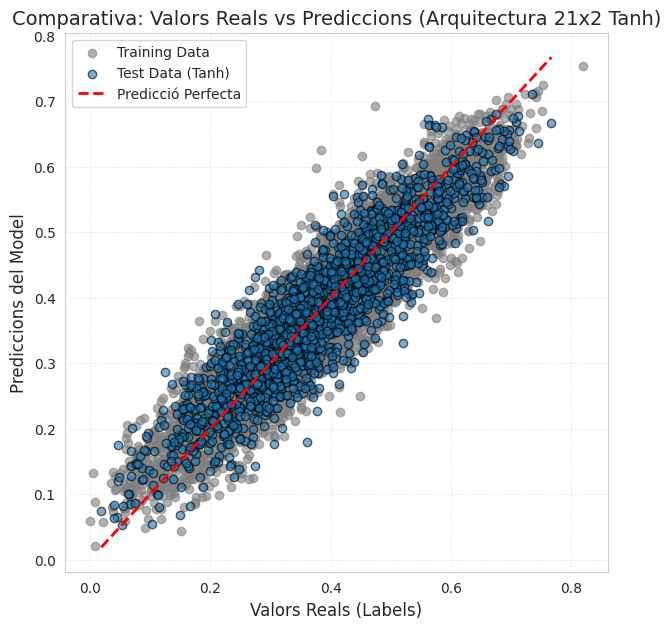

MÈTRIQUES FINALS (TEST):
RMSE:   0.0530
MaxAE:  0.1896


In [ ]:
import matplotlib.pyplot as plt

# 1. Obtenir prediccions per a Train i Test
model.eval()
with torch.no_grad():
    # Prediccions Test
    preds_test_scaled = model(X_test_t).numpy()
    y_pred_test = scaler_y.inverse_transform(preds_test_scaled)
    y_true_test = scaler_y.inverse_transform(y_test_t.numpy())

    # Prediccions Train (per comparar)
    preds_train_scaled = model(X_train_t).numpy()
    y_pred_train = scaler_y.inverse_transform(preds_train_scaled)
    y_true_train = scaler_y.inverse_transform(y_train_t.numpy())

# 2. Crear el gràfic
plt.figure(figsize=(7, 7))

# Punts de Training (en gris, més transparents)
plt.scatter(y_true_train, y_pred_train, color='gray', alpha=0.6, label='Training Data')

# Punts de Test (en blau, els que ens importen)
plt.scatter(y_true_test, y_pred_test, color='#1f77b4', alpha=0.6, edgecolors='k', label='Test Data (Tanh)')

# Línia de perfecció (diagonal y=x)
lims = [min(y_true_test.min(), y_pred_test.min()), max(y_true_test.max(), y_pred_test.max())]
plt.plot(lims, lims, color='red', linestyle='--', lw=2, label='Predicció Perfecta')

# Detalls estètics
plt.title('Comparativa: Valors Reals vs Prediccions (Arquitectura 21x2 Tanh)', fontsize=14)
plt.xlabel('Valors Reals (Labels)', fontsize=12)
plt.ylabel('Prediccions del Model', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()

# 3. Mètriques impreses
from sklearn.metrics import mean_squared_error, max_error
print(f"MÈTRIQUES FINALS (TEST):")
print(f"RMSE:   {np.sqrt(mean_squared_error(y_true_test, y_pred_test)):.4f}")
print(f"MaxAE:  {max_error(y_true_test, y_pred_test):.4f}")

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# 1. Preparació de dades
# (He mantingut la teva estructura de càrrega)
data = pd.read_csv("molrep_mlatom_decimals_coma.csv", encoding='latin1', sep=';')
# Fix: Convertir la columna 'labels' a numèric, gestionant els punts com a separadors de milers
data['labels'] = data['labels'].astype(str).str.replace(',', '.', regex=False).astype(float)
X = data.drop(["name", "labels"], axis=1)
y = data["labels"]

# Fem el split. N es calcularà sol segons el test_size
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=42)

# Normalització (important si labels arriben a ~120)
y_train_scaled = y_train / 120
y_valid_scaled = y_valid / 120

# 2. Configuració de l'anàlisi
I = 10                       # Número de runs
N = len(y_test)              # S'adapta automàticament al teu split
all_runs_preds = np.zeros((N, I))
errors_rmse = []

for i in range(I):
    print(f">>> Entrenant Run {i+1}/{I}...")

    # Definició del model (21 neurones, tanh)
    model = keras.models.Sequential([
        keras.layers.Input(shape=(X_train.shape[1],)),
        keras.layers.Dense(21, activation="tanh"),
        keras.layers.Dense(21, activation="tanh"),
        keras.layers.Dense(1)
    ])

    model.compile(loss="mse", optimizer="adam") # Entrenem amb MSE (estàndard)

    # Entrenament silenciós amb Early Stopping
    model.fit(X_train, y_train_scaled,
              epochs=500,
              validation_data=(X_valid, y_valid_scaled),
              callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)],
              verbose=0)

    # Predicció i des-escalat (* 120)
    preds = model.predict(X_test).flatten() * 120
    all_runs_preds[:, i] = preds

    # Càlcul del RMSE del run actual
    # np.sqrt(mse) = rmse
    rmse_i = np.sqrt(mean_squared_error(y_test, preds))
    errors_rmse.append(rmse_i)
    print(f"Run {i+1} finalitzat. RMSE: {rmse_i:.4f}")

# 3. Càlcul estadístic (Seguint les teves fórmules)
# ------------------------------------------------
e_bar = np.mean(errors_rmse)                    # Mitjana dels RMSE
sigma_err = np.std(errors_rmse, ddof=1)         # Desviació dels errors (estabilitat)
y_n_bar = np.mean(all_runs_preds, axis=1)       # Predicció mitjana per cada molècula
sigma_n = np.std(all_runs_preds, axis=1, ddof=1)# Incertesa individual (SD)
sigma_pred = np.mean(sigma_n)                   # Robustesa global del model

# 4. Exportació a Excel
df_compostos = pd.DataFrame({
    'Valor_Real_DFT': y_test.values,
    'Prediccio_Mitjana': y_n_bar,
    'Incertesa_sigma_n': sigma_n
})

df_metrics = pd.DataFrame({
    'Metrica': ['Average RMSE (e_bar)', 'RMSE Std Dev (sigma_err)', 'Global Robustness (sigma_pred)'],
    'Valor': [e_bar, sigma_err, sigma_pred]
})

with pd.ExcelWriter('resultats_estatistics.xlsx') as writer:
    df_compostos.to_excel(writer, sheet_name='Per_Compost', index=False)
    df_metrics.to_excel(writer, sheet_name='Globals', index=False)

print("\nFITXER GENERAT: 'resultats_estatistics.xlsx'")

>>> Entrenant Run 1/10...
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Run 1 finalitzat. RMSE: 0.0942
>>> Entrenant Run 2/10...
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Run 2 finalitzat. RMSE: 0.1435
>>> Entrenant Run 3/10...
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Run 3 finalitzat. RMSE: 0.1082
>>> Entrenant Run 4/10...
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Run 4 finalitzat. RMSE: 0.0810
>>> Entrenant Run 5/10...
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Run 5 finalitzat. RMSE: 0.1191
>>> Entrenant Run 6/10...
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Run 6 finalitzat. RMSE: 0.1078
>>> Entrenant Run 7/10...
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Run 7 finalitzat. RMSE: 0.2106
>>> Entrenant Run 8/10...
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Run 8 finalitzat. RMSE: 0.0855
>>> Entrenant Run 9/10...
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Run 9 finalitzat. RMSE: 0.0855
>>> Entrenant Run 10/10...
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Run 10 finalitzat. RMSE: 0.2475

FITXER GENERAT: 'resultats_estatistic

In [ ]:
import torch
from torch.utils.data import DataLoader, TensorDataset

# 1. Convertim les dades de Pandas/Numpy a Tensors de PyTorch
# Fem servir .values per obtenir la matriu numèrica i float32 per a la xarxa
X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

# 2. Definim el batch size
BATCH_SIZE = 128

# 3. Creem el Dataset i el DataLoader d'entrenament
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)

print(f"DataLoader preparat amb batches de {BATCH_SIZE}")

DataLoader preparat amb batches de 128


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

# 1. Càrrega i preparació
data = pd.read_csv('molrep_mlatom_decimals_coma.csv', encoding='latin1', sep=';')
# Fix: Convertir la columna 'labels' a numèric, gestionant els punts com a separadors de milers
data['labels'] = data['labels'].astype(str).str.replace(',', '.', regex=False).astype(float)
X = data.drop(columns=['name', 'labels']).values
y = data['labels'].values.reshape(-1, 1)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y)

# Llista per guardar el MSE de cada una de les 10 voltes
all_mse = []

print(f"Iniciant experiment: 10 execucions independents...")



# Primer separem el 15% per a la prova final (Test)
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y_scaled, test_size=0.15, random_state=42)

# Del que queda, separem un 20% per a validació durant l'entrenament
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.20, random_state=42)




for i in range(10):
    # Canviem el random_state a cada volta per variar la partició de dades


    X_train_t = torch.tensor(X_train, dtype=torch.float32)
    y_train_t = torch.tensor(y_train, dtype=torch.float32)
    X_test_t = torch.tensor(X_test, dtype=torch.float32)
    y_test_t = torch.tensor(y_test, dtype=torch.float32)

    # Definició del model (es reinicia a cada iteració del bucle)
    model = nn.Sequential(
        nn.Linear(X_train.shape[1], 21),
        nn.Tanh(),
        nn.Linear(21, 21),
        nn.Tanh(),
        nn.Linear(21, 1)
    )

    optimizer = optim.Adam(model.parameters(), lr=0.005)
    criterion = nn.MSELoss()

    # Entrenament (Early Stopping)
    best_loss = float('inf')
    patience = 20
    counter = 0

    for epoch in range(500):
        model.train()
        optimizer.zero_grad()
        loss = criterion(model(X_train_t), y_train_t)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            v_loss = criterion(model(X_test_t), y_test_t)
            if v_loss < best_loss:
                best_loss = v_loss
                counter = 0
            else:
                counter += 1
            if counter >= patience: break

    # Avaluació final de la volta i des-normalització
    model.eval()
    with torch.no_grad():
        preds_scaled = model(X_test_t).numpy()
        preds_real = scaler_y.inverse_transform(preds_scaled)
        y_real = scaler_y.inverse_transform(y_test)

        mse_run = mean_squared_error(y_real, preds_real)
        all_mse.append(mse_run)
        print(f"Execució {i+1}/10 - MSE: {mse_run:.4f}")

# --- CÀLCUL D'ESTADÍSTIQUES FINALS ---
mean_mse = np.mean(all_mse)
std_mse = np.std(all_mse)

print("\n" + "="*30)
print(f"RESULTATS FINALS (10 RUNS)")
print(f"Mitjana MSE: {mean_mse:.4f}")
print(f"Desviació Estàndard (σ): {std_mse:.4f}")
print(f"Coeficient de Variació: {(std_mse/mean_mse)*100:.2f}%")
print("="*30)

Iniciant experiment: 10 execucions independents...
Execució 1/10 - MSE: 0.0027
Execució 2/10 - MSE: 0.0030
Execució 3/10 - MSE: 0.0028
Execució 4/10 - MSE: 0.0028
Execució 5/10 - MSE: 0.0029
Execució 6/10 - MSE: 0.0030
Execució 7/10 - MSE: 0.0030
Execució 8/10 - MSE: 0.0028
Execució 9/10 - MSE: 0.0028
Execució 10/10 - MSE: 0.0027

RESULTATS FINALS (10 RUNS)
Mitjana MSE: 0.0028
Desviació Estàndard (σ): 0.0001
Coeficient de Variació: 4.09%


search about add batch size 128 / data loader


buscar linea borrada, test size 0,2 change into

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import os
from google.colab import files

# --- 1. Preparación de datos ---
if not os.path.exists("molrep_mlatom_decimals_coma.csv"):
    uploaded = files.upload()

data = pd.read_csv("molrep_mlatom_decimals_coma.csv", encoding='latin1', sep=';')

# FIX: Convertir la columna 'labels' a numèric, gestionant els punts com a separadors de milers
data['labels'] = data['labels'].astype(str).str.replace(',', '.', regex=False).astype(float)

# FIX: Drop rows where 'labels' column has NaN values
data.dropna(subset=['labels'], inplace=True)

X = data.drop(["name", "labels"], axis=1).values # Convertimos a numpy para el dataset
y = data["labels"].values

# División de datos
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=42)

# Normalización de etiquetas
y_train_scaled = y_train / 120
y_valid_scaled = y_valid / 120

# --- NUEVO: Configuración del Data Loader (tf.data.Dataset) ---
BATCH_SIZE = 128

# Creamos el dataset de entrenamiento: Shuffle -> Batch -> Prefetch
train_dataset = tf.data.Dataset.from_tensor_slices((X_train, y_train_scaled))
train_dataset = train_dataset.shuffle(buffer_size=len(X_train)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Creamos el dataset de validación: Batch -> Prefetch (no hace falta shuffle)
valid_dataset = tf.data.Dataset.from_tensor_slices((X_valid, y_valid_scaled))
valid_dataset = valid_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# --- 2. Configuración del análisis (I=10 runs) ---
I = 10
N = len(y_test)
all_runs_preds = np.zeros((N, I))
errors_ei = []

for i in range(I):
    print(f"Entrenant Run {i+1}/10... (Batch Size: {BATCH_SIZE})")

    model = keras.models.Sequential([
        keras.layers.Input(shape=(X_train.shape[1],)),
        keras.layers.Dense(21, activation="tanh"),
        keras.layers.Dense(21, activation="tanh"),
        keras.layers.Dense(1)
    ])

    model.compile(loss="mse", optimizer="adam")

    # Entrenament usando los objetos Dataset
    model.fit(
        train_dataset,
        epochs=500,
        validation_data=valid_dataset,
        callbacks=[keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)],
        verbose=0
    )

    # Predicciones
    preds = model.predict(X_test).flatten() * 120
    all_runs_preds[:, i] = preds

    ei = np.sqrt(mean_squared_error(y_test, preds))
    errors_ei.append(ei)
    print(f"Finalitzat Run {i+1}. RMSE: {ei:.4f}")

# --- 3. Métricas y Guardado (Igual que antes) ---
e_bar = np.mean(errors_ei)
sigma_err = np.std(errors_ei, ddof=1)
y_n_bar = np.mean(all_runs_preds, axis=1)
sigma_n = np.std(all_runs_preds, axis=1, ddof=1)
sigma_pred = np.mean(sigma_n)

df_compostos = pd.DataFrame({
    'Valor_Real_DFT': y_test,
    'Prediccio_Mitjana': y_n_bar,
    'Incertesa_sigma_n': sigma_n
})

df_metrics = pd.DataFrame({
    'Metrica': ['Average Error (e_bar)', 'Error Std Dev (sigma_err)', 'Global Robustness (sigma_pred)'],
    'Valor': [e_bar, sigma_err, sigma_pred]
})

nom_fitxer = 'resultats_estatistics.xlsx'
with pd.ExcelWriter(nom_fitxer) as writer:
    df_compostos.to_excel(writer, sheet_name='Per_Compost', index=False)
    df_metrics.to_excel(writer, sheet_name='Globals', index=False)

print(f"\n--- PROCÉS FINALITZAT ---")
print(f"Error mitjà (e_bar): {e_bar:.4f}")
print(f"Robustesa global (sigma_pred): {sigma_pred:.4f}")

files.download(nom_fitxer)

Entrenant Run 1/10... (Batch Size: 128)
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Finalitzat Run 1. RMSE: 0.1392
Entrenant Run 2/10... (Batch Size: 128)
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Finalitzat Run 2. RMSE: 0.1795
Entrenant Run 3/10... (Batch Size: 128)
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Finalitzat Run 3. RMSE: 0.2710
Entrenant Run 4/10... (Batch Size: 128)
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Finalitzat Run 4. RMSE: 0.1792
Entrenant Run 5/10... (Batch Size: 128)
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Finalitzat Run 5. RMSE: 0.1399
Entrenant Run 6/10... (Batch Size: 128)
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Finalitzat Run 6. RMSE: 0.1346
Entrenant Run 7/10... (Batch Size: 128)
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Finalitzat Run 7. RMSE: 0.2238
Entrenant Run 8/10... (Batch Size: 128)
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Finalitzat Run 8. RMSE: 0.1459
Entrenant Run 9/10... (Batch Size: 128)
59/59 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Finalitzat Run 9. RMSE: 0.1245
Entrenant 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Carreguem el fitxer
df = pd.read_csv('molrep_mlatom_decimals_coma.csv', encoding='latin1', sep=';')

# Fix: Convertir la columna 'labels' a numèric, gestionant els punts com a separadors de milers
df['labels'] = df['labels'].astype(str).str.replace(',', '.', regex=False).astype(float)

# Seleccionem només les columnes numèriques per al clustering (x1 a x24)
# Ignorem 'name' i 'labels' per a que no influisquen en la creació dels grups
X = df.drop(columns=['name', 'labels'])

print(f"Dades llistes: {X.shape[0]} mostres amb {X.shape[1]} característiques.")

Dades llistes: 9364 mostres amb 24 característiques.


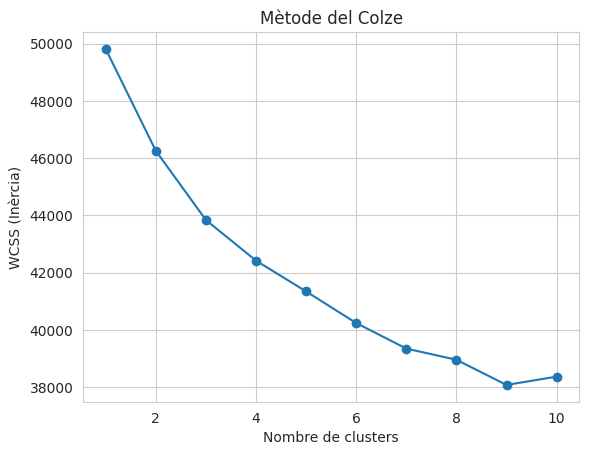

In [ ]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('Mètode del Colze')
plt.xlabel('Nombre de clusters')
plt.ylabel('WCSS (Inèrcia)')
plt.show()

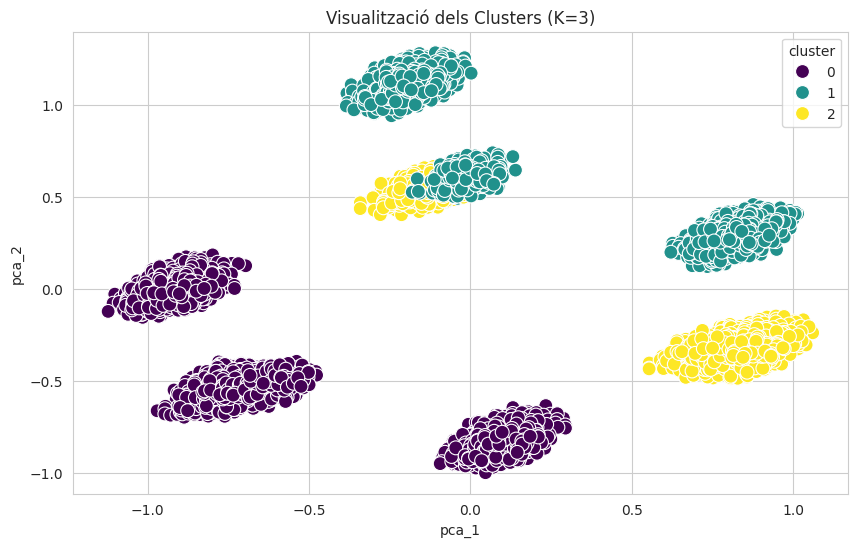

In [ ]:
# Apliquem K-Means
n_clusters = 3
kmeans = KMeans(n_clusters=n_clusters, random_state=42)
df['cluster'] = kmeans.fit_predict(X)

# Reducció de dimensió per a visualitzar
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
df['pca_1'] = X_pca[:, 0]
df['pca_2'] = X_pca[:, 1]

# Gràfic de dispersió
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='pca_1', y='pca_2', hue='cluster', palette='viridis', s=100)
plt.title(f'Visualització dels Clusters (K={n_clusters})')
plt.show()

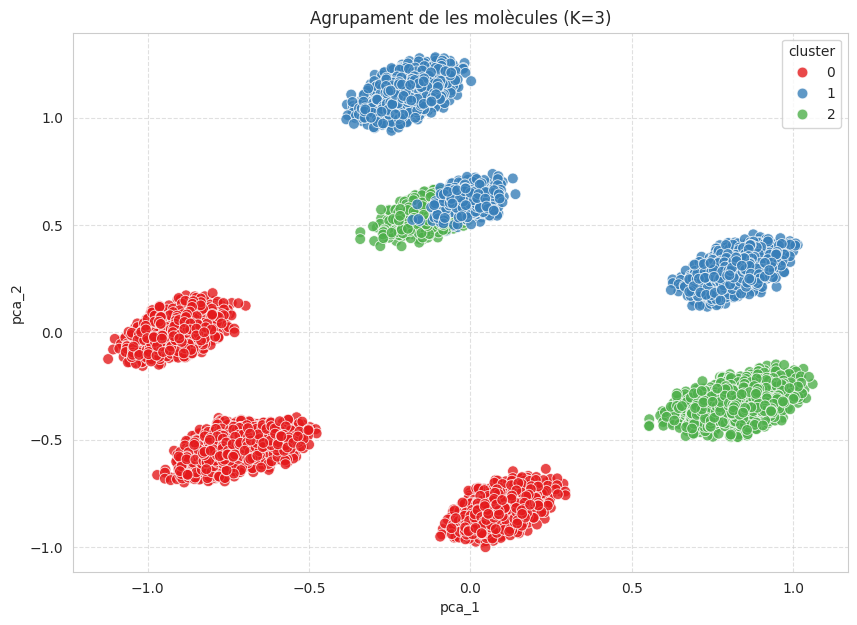

Quantitat de mostres per clúster:
cluster
0    3985
1    3034
2    2345
Name: count, dtype: int64


In [ ]:
# 1. Apliquem el K-Means amb k=3
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42)
df['cluster'] = kmeans.fit_predict(X)

# 2. Reducció de dimensionalitat (PCA) per visualitzar en 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
df['pca_1'] = X_pca[:, 0]
df['pca_2'] = X_pca[:, 1]

# 3. Dibuixem els resultats
plt.figure(figsize=(10, 7))
sns.scatterplot(x='pca_1', y='pca_2', hue='cluster', data=df, palette='Set1', s=60, alpha=0.8)
plt.title('Agrupament de les molècules (K=3)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 4. Vegem quants elements hi ha en cada grup
print("Quantitat de mostres per clúster:")
print(df['cluster'].value_counts())

In [ ]:
# Això et traurà una taula amb els valors mitjans de cada característica per grup
# Excloem la columna 'name' perquè no és numèrica i causaria un error amb .mean()
resum_clusters = df.drop(columns=['name']).groupby('cluster').mean()
display(resum_clusters)

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,...,x18,x19,x20,x21,x22,x23,x24,labels,pca_1,pca_2
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.469511,0.525471,0.445671,0.300878,0.315433,0.273275,0.110414,0.516186,0.500125,0.489586,...,0.514931,0.494605,0.476537,0.511669,0.494354,0.503890,0.514178,0.383985,-0.535576,-0.452550
1,0.486486,0.496045,0.406065,0.402769,0.404087,0.193144,0.000000,0.501648,0.493408,0.498022,...,0.505933,0.496374,0.491430,0.499011,0.490771,0.499011,0.487805,0.396949,0.247614,0.683497
2,0.502772,0.501919,0.249041,0.753945,0.246055,0.000000,0.000000,0.510874,0.498081,0.486994,...,0.495096,0.489552,0.510021,0.506610,0.489126,0.514712,0.502772,0.368652,0.589769,-0.115274


Silhouette Score: 0.0839
Variància explicada pels 2 primers components: 15.08%


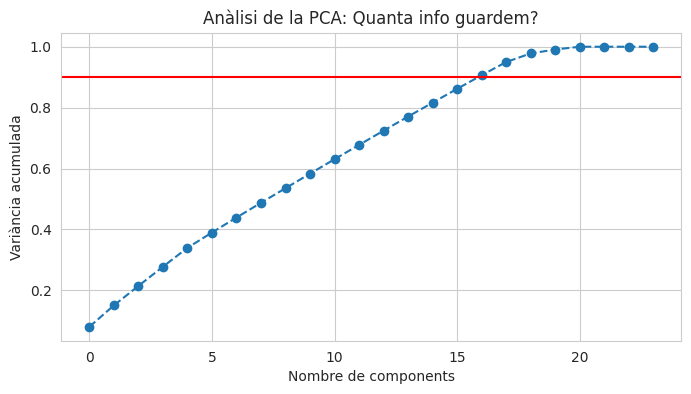

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import numpy as np

# 1. Calculem el Silhouette Score per a K=4 (el que t'ha eixit a tu)
score = silhouette_score(X, df['cluster'])
print(f"Silhouette Score: {score:.4f}")

# 2. Anàlisi profunda de la PCA
pca_full = PCA().fit(X)
variancia_acumulada = np.cumsum(pca_full.explained_variance_ratio_)

print(f"Variància explicada pels 2 primers components: {variancia_acumulada[1]*100:.2f}%")

# Gràfic de variància per saber quants components importen realment
plt.figure(figsize=(8, 4))
plt.plot(variancia_acumulada, marker='o', linestyle='--')
plt.xlabel('Nombre de components')
plt.ylabel('Variància acumulada')
plt.title('Anàlisi de la PCA: Quanta info guardem?')
plt.axhline(y=0.90, color='r', linestyle='-') # Línia del 90%
plt.show()

In [ ]:
import pandas as pd
df = pd.read_csv('molrep_mlatom_decimals_coma.csv', sep=';', decimal=',')
print(df.head())
print(df.info())

                          name  x1  x2  x3  x4  x5  x6  x7  x8  x9  ...  x16  \
0  lin.cc.2.23.2.1.000-010-001   0   0   0   1   0   0   0   1   1  ...    0   
1  lin.cc.2.23.2.1.000-101-000   0   0   0   1   0   0   0   1   1  ...    0   
2  lin.cc.2.23.2.1.001-010-000   0   0   0   1   0   0   0   1   1  ...    0   
3  lin.cc.2.23.2.1.010-000-010   0   0   0   1   0   0   0   1   1  ...    0   
4  lin.cc.2.23.2.2.001-010-011   0   0   0   1   0   0   0   1   1  ...    0   

   x17  x18  x19  x20  x21  x22  x23  x24    labels  
0    0    0    0    1    0    0    0    1  0.510140  
1    0    0    1    0    1    0    0    0  0.377116  
2    0    1    0    1    0    0    0    0  0.535529  
3    1    0    0    0    0    0    1    0  0.651319  
4    0    1    0    1    0    0    1    1  0.381267  

[5 rows x 26 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9364 entries, 0 to 9363
Data columns (total 26 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  -------------- 

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

X = df.drop(columns=['name', 'labels'])
y = df['labels']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

mlp = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
mlp.fit(X_train, y_train)

preds = mlp.predict(X_test)
print("R2:", r2_score(y_test, preds))
print("RMSE:", np.sqrt(mean_squared_error(y_test, preds)))

R2: 0.7923525304940136
RMSE: 0.059824799991221964


Plot saved successfully!


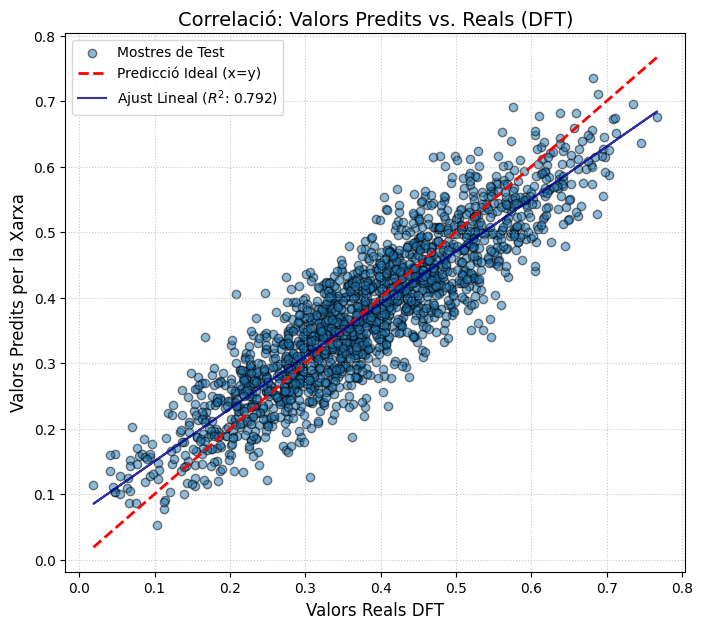

In [ ]:
import matplotlib.pyplot as plt
from scipy import stats

# Calculate fit line
slope, intercept, r_value, p_value, std_err = stats.linregress(y_test, preds)
line = slope * y_test + intercept

plt.figure(figsize=(8, 7))
plt.scatter(y_test, preds, alpha=0.5, color='#1f77b4', edgecolors='k', label=f'Mostres de Test')
lims = [min(min(y_test), min(preds)), max(max(y_test), max(preds))]
plt.plot(lims, lims, color='red', linestyle='--', linewidth=2, label='Predicció Ideal (x=y)')
plt.plot(y_test, line, color='darkblue', alpha=0.8, label=f'Ajust Lineal ($R^2$: {r2_score(y_test, preds):.3f})')
plt.title('Correlació: Valors Predits vs. Reals (DFT)', fontsize=14)
plt.xlabel('Valors Reals DFT', fontsize=12)
plt.ylabel('Valors Predits per la Xarxa', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.savefig('test_plot.png')
print("Plot saved successfully!")